# Energia e accuracy: analisi finale

Questo notebook legge i risultati prodotti da `finish_experiment.sh`, senza avviare reti e senza modificare i run energetici originali.

Il file `accuracy_by_sample.csv` viene creato **automaticamente** dal completamento. Le frequenze della legenda sono quelle registrate nelle tabelle validate. PCK e' espresso in **percentuale**, MPJPE in **pixel**. La misura energetica comprende CPU package e GPU device; non e' attribuita al singolo processo e non rappresenta tutta la macchina.

La sessione ha prodotto 84 righe di accuracy e 420 run energetici. La **final analysis** applica pero' un controllo comune di validita' temporale ed esclude DHP19 D09/D10 da tutti gli aggregati finali, lasciando 12 sequenze eH36M e 10 sequenze DHP19 per metodo. Nessun esperimento viene rilanciato.


In [1]:
from pathlib import Path
import os
import sys
import json
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display

# Sessione realmente eseguita. Non contiene frequenze hard-coded nei grafici.
SESSION = "energy_accuracy_final_5hz_ofk"
# Di norma lasciare None: vengono verificati sia il mount /data sia HOME/data.
RESULTS_DIR = None

# Il notebook usa lo stesso modulo dello script, evitando due implementazioni diverse.
package_candidates = []
if os.environ.get("MOVEENET_FINAL_PACKAGE"):
    package_candidates.append(Path(os.environ["MOVEENET_FINAL_PACKAGE"]))
for parent in (Path.cwd(), *Path.cwd().parents):
    package_candidates.extend((parent, parent / "moveEnetFlow/experiments/ExpFinal"))
PACKAGE = next((p for p in package_candidates if (p / "final_analysis.py").is_file()), None)
if PACKAGE is None:
    raise RuntimeError("Aprire questo notebook dalla directory ExpFinal/notebooks nella repository in cui e' stato estratto il pacchetto.")
sys.path.insert(0, str(PACKAGE))
from final_analysis import plot_tradeoff, plot_tradeoff_all, plot_energy, plot_runtime

if RESULTS_DIR is None:
    candidates = []
    if os.environ.get("MOVEENET_FINAL_RESULTS"):
        candidates.append(Path(os.environ["MOVEENET_FINAL_RESULTS"]))
    candidates.extend((Path("/data/MoveEnet_OFK_results/Final") / SESSION,
                       Path.home() / "data/MoveEnet_OFK_results/Final" / SESSION))
    RESULTS_DIR = next((p for p in candidates if (p / "tables/energy_runtime_summary.csv").is_file()), None)
if RESULTS_DIR is None:
    raise RuntimeError("Prima eseguire finish_experiment.sh --prepare-only oppure il completamento --resume, dall'host. Nessun CSV accuracy manuale deve essere creato.")
RESULTS_DIR = Path(RESULTS_DIR).expanduser().resolve()
TABLES = RESULTS_DIR / "tables"
FIGURES = RESULTS_DIR / "figures"
completion = json.loads((RESULTS_DIR / "completion.json").read_text())
audit = json.loads((RESULTS_DIR / "audit_energy.json").read_text())
print("Directory risultati:", RESULTS_DIR)
print("Run energia OK unici:", audit["successful_unique_runs"])
print("Accuracy completate:", completion["accuracy_completed"], "/", completion["accuracy_required"])
for warning in audit.get("warnings", []):
    print("DA ESAMINARE:", warning)


Directory risultati: /data/MoveEnet_OFK_results/Final/energy_accuracy_final_5hz_ofk
Run energia OK unici: 420
Accuracy completate: 84 / 84
DA ESAMINARE: Runtime anomalo da esaminare: ('h36m', 'H04', 'yolo') tempi=[27.693281801, 28.448229428, 28.268494937, 161.912793747, 26.230995587]


## Final-analysis quality-control exclusion

For the final DHP19 aggregate, recordings **D09** and **D10** are excluded across **all methods and all reported metrics**.

The exclusion is based on the temporal-coverage diagnostic, not on accuracy: for these recordings the prediction timestamps extend substantially beyond the available ground-truth interval, producing many rows outside the GT span. The raw experimental outputs are left unchanged; only the final aggregation/plotting stage applies this common validity mask.

Consequently, the final figures use:
- eH36M: 12 sequences per method;
- DHP19: 10 valid sequences per method.

The experiment still acquired 420 energy runs in total. The final common-subset analysis omits the 30 runs belonging to D09/D10 (2 sequences x 3 DHP19 methods x 5 repetitions), so 390 energy runs contribute to the reported aggregates.


In [2]:
import numpy as np

# Final-analysis QC mask. Keep this centralized so every metric uses the same subset.
EXCLUDED_SAMPLES = {("dhp19", "D09"), ("dhp19", "D10")}
BOOTSTRAP_SEED = 20260911
BOOTSTRAP_REPLICATES = 5000
FINAL_FIGURE_SUFFIX = "_valid_subset"

def apply_sample_exclusions(df):
    out = df.copy()
    mask = pd.Series(False, index=out.index)
    for dataset, sample_id in EXCLUDED_SAMPLES:
        mask |= ((out["dataset"] == dataset) & (out["sample_id"] == sample_id))
    return out.loc[~mask].copy()

def expected_sequence_count(dataset):
    return 10 if dataset == "dhp19" else 12

def _ci95(values):
    lo, hi = np.quantile(values, [0.025, 0.975])
    return float(lo), float(hi)

def summarize_runtime_valid_subset(raw, base_summary):
    rows = []

    for _, base in base_summary.iterrows():
        dataset = base["dataset"]
        model = base["model"]
        g = raw[(raw["dataset"] == dataset) & (raw["model"] == model)].copy()
        g = g.sort_values("sample_id").reset_index(drop=True)

        expected = expected_sequence_count(dataset)
        n = g["sample_id"].nunique()
        if n != expected or len(g) != expected:
            raise RuntimeError(
                f"Subset finale inatteso per {dataset}/{model}: "
                f"{n} sample unici, {len(g)} righe; attesi {expected}."
            )

        E = pd.to_numeric(g["energy_j"], errors="raise").to_numpy(float)
        E_cpu = pd.to_numeric(g["cpu_energy_j"], errors="raise").to_numpy(float)
        E_gpu = pd.to_numeric(g["gpu_energy_j"], errors="raise").to_numpy(float)
        T = pd.to_numeric(g["sequence_wall_seconds"], errors="raise").to_numpy(float)
        D = pd.to_numeric(g["input_span_s"], errors="raise").to_numpy(float)

        rng = np.random.default_rng(BOOTSTRAP_SEED)
        ix = rng.integers(0, len(g), size=(BOOTSTRAP_REPLICATES, len(g)))

        boot_energy = E[ix].mean(axis=1)
        boot_wall = T[ix].mean(axis=1)
        boot_rtf = T[ix].sum(axis=1) / D[ix].sum(axis=1)
        boot_normalized_energy = E[ix].sum(axis=1) / D[ix].sum(axis=1)

        energy_lo, energy_hi = _ci95(boot_energy)
        wall_lo, wall_hi = _ci95(boot_wall)
        rtf_lo, rtf_hi = _ci95(boot_rtf)
        norm_lo, norm_hi = _ci95(boot_normalized_energy)

        row = base.to_dict()
        row.update({
            "n_sequences": expected,
            "energy_mean_j": float(E.mean()),
            "energy_sequence_sd_j": float(E.std(ddof=1)),
            "cpu_energy_mean_j": float(E_cpu.mean()),
            "gpu_energy_mean_j": float(E_gpu.mean()),
            "wall_mean_s": float(T.mean()),
            "wall_sequence_sd_s": float(T.std(ddof=1)),
            "input_span_mean_s": float(D.mean()),
            # Ratio-of-sums, matching the original final-analysis convention.
            "real_time_factor": float(T.sum() / D.sum()),
            "speed_vs_realtime": float(D.sum() / T.sum()),
            "energy_j_per_input_second": float(E.sum() / D.sum()),
            "combined_mean_power_w": float(E.sum() / T.sum()),
            "cpu_mean_power_w": float(E_cpu.sum() / T.sum()),
            "gpu_mean_power_w": float(E_gpu.sum() / T.sum()),
            "amortized_ms_per_nominal_output_slot":
                float(1000.0 * T.sum() / (D.sum() * float(base["output_hz"]))),
            "energy_ci95_low": energy_lo,
            "energy_ci95_high": energy_hi,
            "wall_ci95_low": wall_lo,
            "wall_ci95_high": wall_hi,
            "rtf_ci95_low": rtf_lo,
            "rtf_ci95_high": rtf_hi,
            "normalized_energy_ci95_low": norm_lo,
            "normalized_energy_ci95_high": norm_hi,
        })
        rows.append(row)

    return pd.DataFrame(rows)[base_summary.columns]

def summarize_accuracy_valid_subset(paired, runtime_summary, base_accuracy_summary):
    rows = []

    for _, runtime_row in runtime_summary.iterrows():
        dataset = runtime_row["dataset"]
        model = runtime_row["model"]
        g = paired[(paired["dataset"] == dataset) & (paired["model"] == model)].copy()
        g = g.sort_values("sample_id").reset_index(drop=True)

        expected = expected_sequence_count(dataset)
        n = g["sample_id"].nunique()
        if n != expected or len(g) != expected:
            raise RuntimeError(
                f"Subset accuracy inatteso per {dataset}/{model}: "
                f"{n} sample unici, {len(g)} righe; attesi {expected}."
            )

        n_points = pd.to_numeric(g["n_points"], errors="raise").to_numpy(float)
        correct = pd.to_numeric(g["pck_0.2_correct_points"], errors="raise").to_numpy(float)
        sum_err = pd.to_numeric(g["sum_err_px"], errors="raise").to_numpy(float)

        rng = np.random.default_rng(BOOTSTRAP_SEED)
        ix = rng.integers(0, len(g), size=(BOOTSTRAP_REPLICATES, len(g)))

        boot_pck = 100.0 * correct[ix].sum(axis=1) / n_points[ix].sum(axis=1)
        boot_mpjpe = sum_err[ix].sum(axis=1) / n_points[ix].sum(axis=1)
        pck_lo, pck_hi = _ci95(boot_pck)
        mpjpe_lo, mpjpe_hi = _ci95(boot_mpjpe)

        row = runtime_row.to_dict()
        row.update({
            "pck_weighted_percent": float(100.0 * correct.sum() / n_points.sum()),
            "mpjpe_weighted_px": float(sum_err.sum() / n_points.sum()),
            "pck_sequence_macro_percent": float(pd.to_numeric(g["pck"], errors="raise").mean()),
            "mpjpe_sequence_macro_px": float(pd.to_numeric(g["mpjpe"], errors="raise").mean()),
            "total_evaluated_joint_points": int(n_points.sum()),
            "accuracy_aggregation": "point_weighted_as_ExpA",
            "min_observed_output_hz": float(g["observed_output_hz"].min()),
            "max_observed_output_hz": float(g["observed_output_hz"].max()),
            "pck_ci95_low": pck_lo,
            "pck_ci95_high": pck_hi,
            "mpjpe_ci95_low": mpjpe_lo,
            "mpjpe_ci95_high": mpjpe_hi,
        })
        rows.append(row)

    result = pd.DataFrame(rows)
    return result[base_accuracy_summary.columns]

print("QC exclusion attiva:", sorted(EXCLUDED_SAMPLES))


QC exclusion attiva: [('dhp19', 'D09'), ('dhp19', 'D10')]


## Misure energetiche

Cinque ripetizioni vengono mediate prima per sequenza-camera e metodo. I punti del grafico rappresentano le 12 sequenze del dataset, non 60 sequenze indipendenti. Le deviazioni delle ripetizioni restano disponibili nella tabella per sample.

`energy_mean_j` e' energia media per sequenza. `combined_mean_power_w` e' energia divisa per tempo wall-clock; `energy_j_per_input_second` normalizza invece per il tempo della sequenza del dataset: **non e' la stessa grandezza**.

,dataset,method,net_hz,n_sequences,energy_mean_j,cpu_energy_mean_j,gpu_energy_mean_j,combined_mean_power_w,wall_mean_s
0,dhp19,EventPointPose,200.0,10,1484.417021,1057.996701,426.420320,50.272213,29.527584
1,dhp19,MoveEnetOFK,5.0,10,173.519077,91.806117,81.712960,32.157750,5.395871
2,dhp19,MoveEnet only,200.0,10,934.923702,563.896562,371.027140,36.529002,25.594011
3,h36m,MoveEnetOFK,5.0,12,357.981398,203.371098,154.610300,32.163672,11.129992
4,h36m,MoveEnet only,50.0,12,944.404895,568.019745,376.385150,35.757981,26.411024
5,h36m,OpenPose,50.0,12,9695.859773,3604.029973,6091.829800,54.501788,177.899846
6,h36m,YOLOPose,50.0,12,1179.163730,609.413263,569.750467,40.958535,28.789206


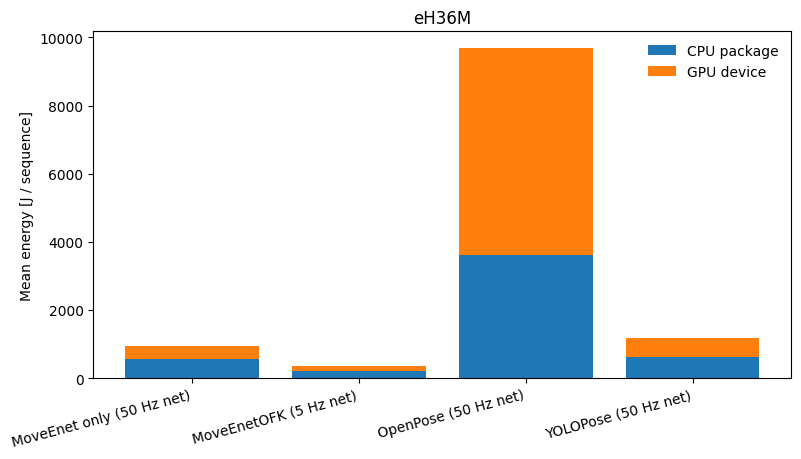

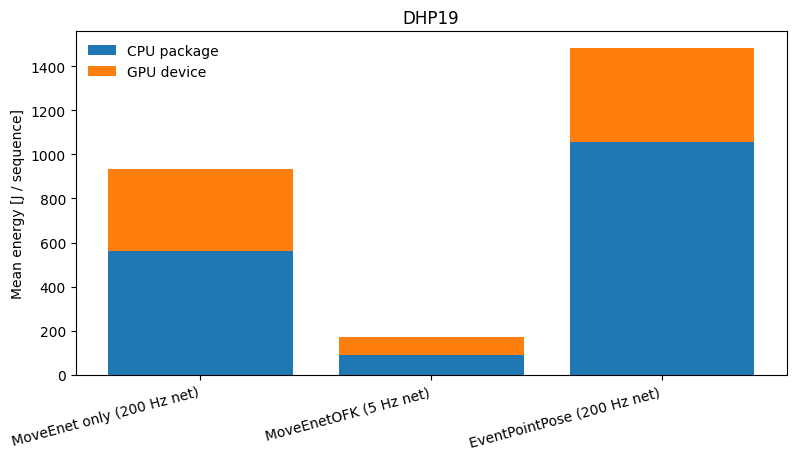

Summary filtrato: /data/MoveEnet_OFK_results/Final/energy_accuracy_final_5hz_ofk/tables/energy_runtime_summary_valid_subset.csv


In [3]:
energy_runtime_all = pd.read_csv(TABLES / "energy_runtime_by_sample.csv")
base_runtime_summary = pd.read_csv(TABLES / "energy_runtime_summary.csv")

energy_runtime = apply_sample_exclusions(energy_runtime_all)
summary_runtime = summarize_runtime_valid_subset(energy_runtime, base_runtime_summary)

summary_runtime.to_csv(TABLES / "energy_runtime_summary_valid_subset.csv", index=False)
energy_runtime.to_csv(TABLES / "energy_runtime_by_sample_valid_subset.csv", index=False)

display(summary_runtime[["dataset", "method", "net_hz", "n_sequences", "energy_mean_j",
                         "cpu_energy_mean_j", "gpu_energy_mean_j", "combined_mean_power_w", "wall_mean_s"]])

for dataset in ("h36m", "dhp19"):
    figure = plot_energy(summary_runtime, dataset)
    display(figure)
    figure.savefig(FIGURES / f"{dataset}_energy{FINAL_FIGURE_SUFFIX}.png", dpi=300, bbox_inches="tight")
    figure.savefig(FIGURES / f"{dataset}_energy{FINAL_FIGURE_SUFFIX}.svg", bbox_inches="tight")
    plt.close(figure)

print("Summary filtrato:", TABLES / "energy_runtime_summary_valid_subset.csv")


## Energy vs PCK e MPJPE

Le metriche riproducono il notebook ExpA della repository: GT interpolata ai timestamp delle predizioni, riferimento PCK spalla destra--anca sinistra (joint 1 e 5), 13 joint. La stima principale e' pesata per il numero di joint valutati; anche le medie per sequenza sono esportate. Nessuna predizione viene interpolata per simulare una rete a frequenza maggiore.

Le barre sono intervalli bootstrap percentile 95% sulle unita' sequenza-camera del **subset finale comune**: 12 per eH36M e 10 per DHP19. Le cinque ripetizioni energetiche vengono aggregate prima a livello di sequenza. Le barre sono descrittive di questo insieme; non stimano l'incertezza su soggetti indipendenti o la variabilita' stocastica dell'accuracy.

PCK: migliore verso alto/sinistra. MPJPE: migliore verso basso/sinistra.


,dataset,method,net_hz,n_sequences,energy_mean_j,pck_weighted_percent,mpjpe_weighted_px,pck_sequence_macro_percent,mpjpe_sequence_macro_px
0,dhp19,EventPointPose,200.0,10,1484.417021,34.904943,21.747263,35.214641,21.655671
1,dhp19,MoveEnetOFK,5.0,10,173.519077,84.793301,6.933765,84.911469,6.914549
2,dhp19,MoveEnet only,200.0,10,934.923702,89.605836,6.078892,89.784722,6.041667
3,h36m,MoveEnetOFK,5.0,12,357.981398,76.692290,14.877907,76.800378,15.091965
4,h36m,MoveEnet only,50.0,12,944.404895,81.533404,12.788127,81.998031,12.728378
5,h36m,OpenPose,50.0,12,9695.859773,93.040967,13.979034,93.456721,14.587448
6,h36m,YOLOPose,50.0,12,1179.163730,90.686921,10.106258,91.039493,10.173703


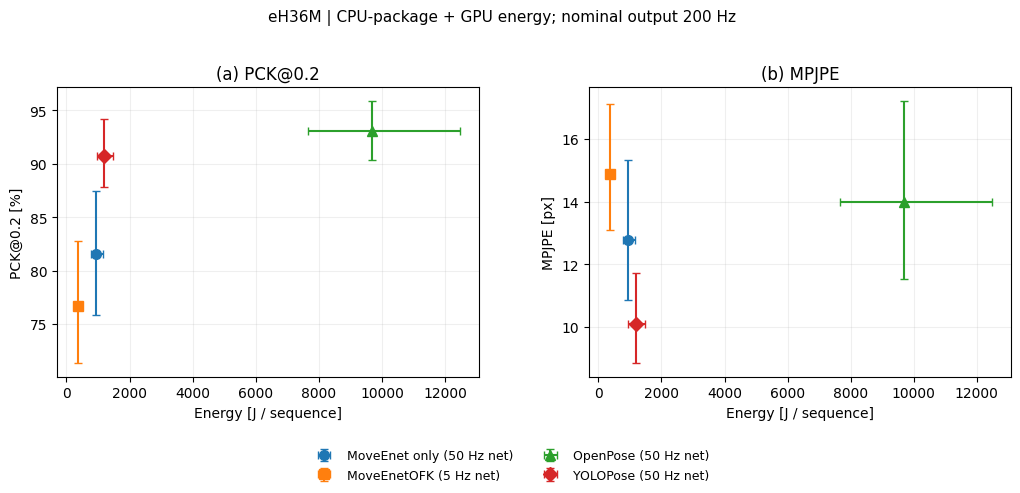

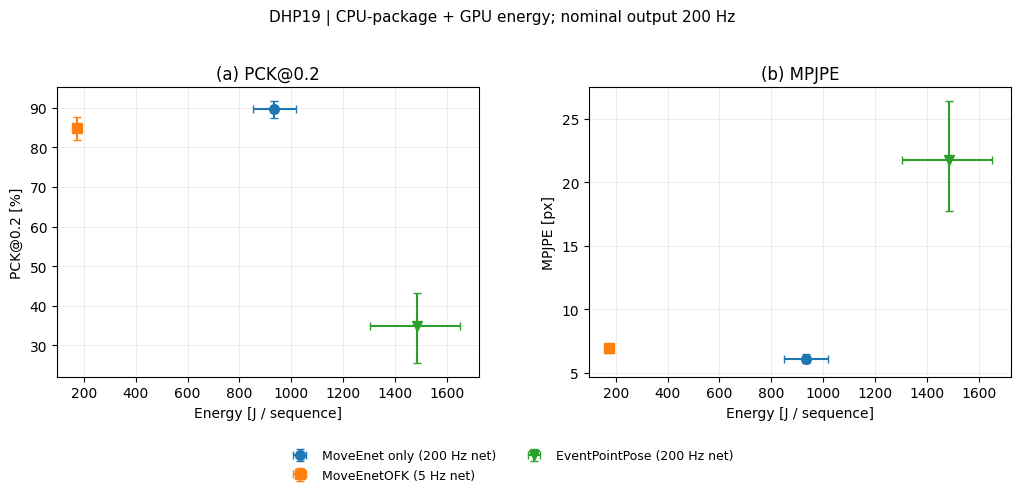

In [4]:
accuracy_ready = bool(completion["accuracy_complete"])
if accuracy_ready:
    accuracy_all = pd.read_csv(TABLES / "accuracy_by_sample.csv")
    paired_all = pd.read_csv(TABLES / "energy_accuracy_by_sample.csv")
    base_accuracy_summary = pd.read_csv(TABLES / "energy_accuracy_summary.csv")

    accuracy = apply_sample_exclusions(accuracy_all)
    paired = apply_sample_exclusions(paired_all)
    summary = summarize_accuracy_valid_subset(paired, summary_runtime, base_accuracy_summary)

    # 48 eH36M rows + 30 DHP19 rows = 78 final per-sample accuracy rows.
    if len(accuracy) != 78 or len(paired) != 78:
        raise RuntimeError(f"Attese 78 righe dopo il QC; accuracy={len(accuracy)}, paired={len(paired)}")

    accuracy.to_csv(TABLES / "accuracy_by_sample_valid_subset.csv", index=False)
    paired.to_csv(TABLES / "energy_accuracy_by_sample_valid_subset.csv", index=False)
    summary.to_csv(TABLES / "energy_accuracy_summary_valid_subset.csv", index=False)

    display(summary[["dataset", "method", "net_hz", "n_sequences", "energy_mean_j",
                     "pck_weighted_percent", "mpjpe_weighted_px",
                     "pck_sequence_macro_percent", "mpjpe_sequence_macro_px"]])

    for dataset in ("h36m", "dhp19"):
        figure = plot_tradeoff(summary, dataset)
        display(figure)
        figure.savefig(FIGURES / f"{dataset}_energy_accuracy{FINAL_FIGURE_SUFFIX}.png",
                       dpi=300, bbox_inches="tight")
        figure.savefig(FIGURES / f"{dataset}_energy_accuracy{FINAL_FIGURE_SUFFIX}.svg",
                       bbox_inches="tight")
        plt.close(figure)
else:
    print("Figura finale non prodotta: accuracy ancora incompleta. Riprendere finish_experiment.sh --resume; non rilanciare l'energia.")


## Unica figura 2 x 2 per il paper

Le versioni separate per dataset e questa versione combinata sono gia' salvate dallo script in PNG e SVG dentro `figures/`.

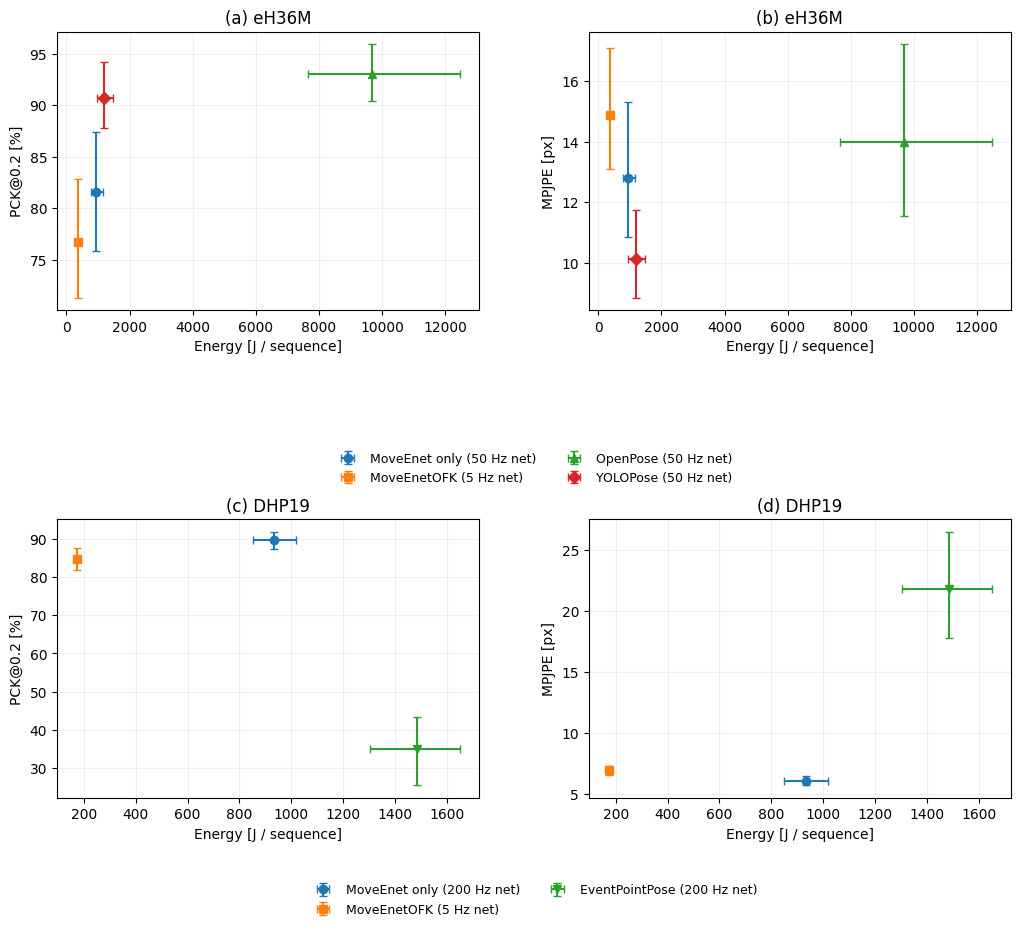

PNG: /data/MoveEnet_OFK_results/Final/energy_accuracy_final_5hz_ofk/figures/energy_accuracy_both_datasets_valid_subset.png
SVG: /data/MoveEnet_OFK_results/Final/energy_accuracy_final_5hz_ofk/figures/energy_accuracy_both_datasets_valid_subset.svg


In [5]:
if accuracy_ready:
    figure = plot_tradeoff_all(summary)
    display(figure)
    png = FIGURES / f"energy_accuracy_both_datasets{FINAL_FIGURE_SUFFIX}.png"
    svg = FIGURES / f"energy_accuracy_both_datasets{FINAL_FIGURE_SUFFIX}.svg"
    figure.savefig(png, dpi=300, bbox_inches="tight")
    figure.savefig(svg, bbox_inches="tight")
    plt.close(figure)
    print("PNG:", png)
    print("SVG:", svg)


## Normalizzazione per durata del dato

La versione seguente usa $\sum_s E_s / \sum_s D_s$ sull'asse X, in joule per secondo di input. Consente di esplicitare la durata delle sequenze. Non rappresenta la potenza media misurata in tempo reale.

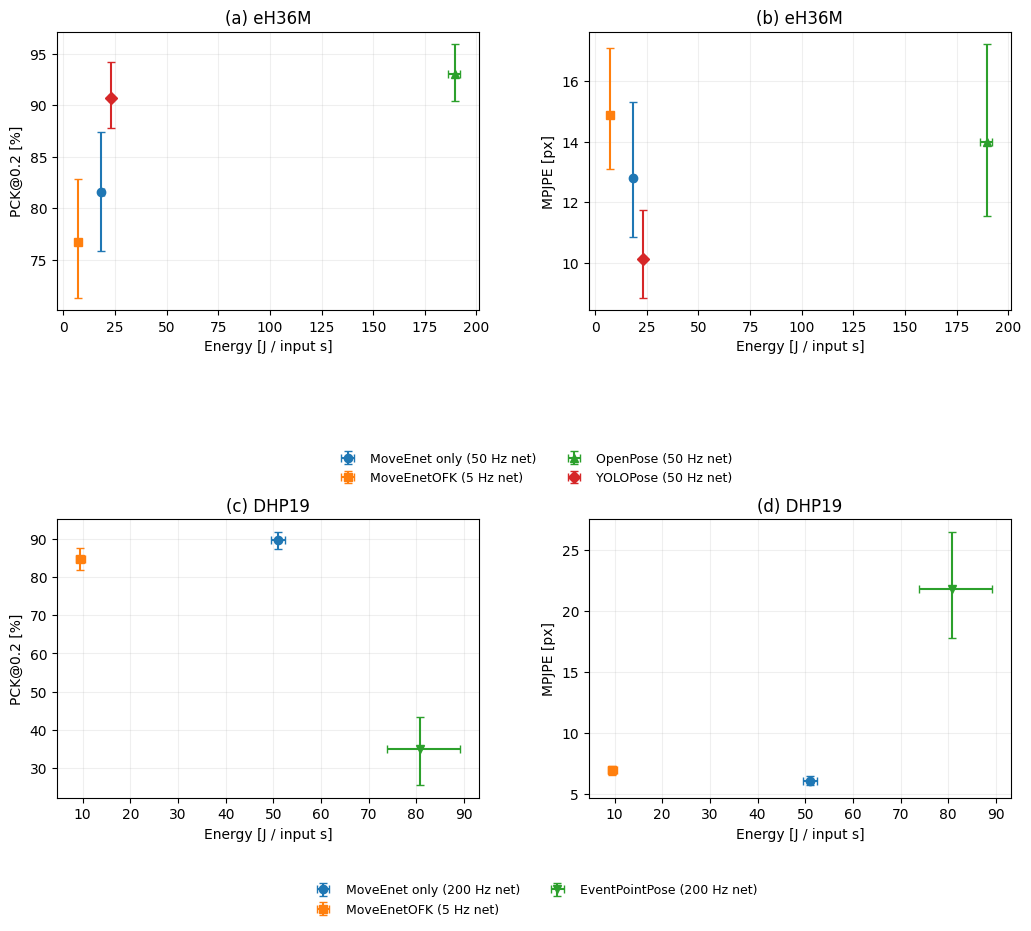

In [6]:
if accuracy_ready:
    figure = plot_tradeoff_all(summary, normalized=True)
    display(figure)
    png = FIGURES / f"energy_accuracy_both_datasets_normalized{FINAL_FIGURE_SUFFIX}.png"
    svg = FIGURES / f"energy_accuracy_both_datasets_normalized{FINAL_FIGURE_SUFFIX}.svg"
    figure.savefig(png, dpi=300, bbox_inches="tight")
    figure.savefig(svg, bbox_inches="tight")
    plt.close(figure)


## Copertura e frequenze effettive

Il periodo configurato e' nominale. MoveEnet usa scadenze relative ai pacchetti: non e' corretto dichiarare 200 output effettivi/s solo perche' `output_period=0.005`. Gli scheduler ZOH di OpenPose, YOLOPose ed EventPointPose sono controllati sulla sequenza realmente scritta.

D09 e D10 restano visibili nel file diagnostico originale, ma vengono esclusi dal **subset finale** perche' falliscono il controllo di copertura temporale. La tabella mostrata qui sotto usa lo stesso subset delle figure finali.


In [7]:
if accuracy_ready:
    coverage_all = pd.read_csv(TABLES / "accuracy_coverage_diagnostics.csv")
    coverage = apply_sample_exclusions(coverage_all)
    coverage.to_csv(TABLES / "accuracy_coverage_diagnostics_valid_subset.csv", index=False)

    display(coverage.groupby(["dataset", "model"]).agg(
        samples=("sample_id", "nunique"),
        minimum_output_hz=("observed_output_hz", "min"),
        maximum_output_hz=("observed_output_hz", "max"),
        nonfinite_rows=("n_nonfinite_rows_excluded", "sum"),
        outside_gt_rows=("n_rows_outside_gt_span", "sum"),
        maximum_gap_s=("max_output_gap_s", "max")))
    print("Diagnostica originale:", TABLES / "accuracy_coverage_diagnostics.csv")
    print("Diagnostica subset finale:", TABLES / "accuracy_coverage_diagnostics_valid_subset.csv")


samples  minimum_output_hz  maximum_output_hz  \
dataset model                                                           
dhp19   eventpointpose       10         200.000000         200.000000   
        moveenetofk          10         180.574427         192.332773   
        movenet              10         180.574427         192.332773   
h36m    moveenetofk          12         184.576095         192.802489   
        movenet              12         184.576095         192.802489   
        openpose             12         200.000000         200.000000   
        yolo                 12         200.000000         200.000000   

                        nonfinite_rows  outside_gt_rows  maximum_gap_s  
dataset model                                                           
dhp19   eventpointpose               0                0       0.005000  
        moveenetofk                  0               13       0.121088  
        movenet                      0               13       0.121088  
h36m    moveenetofk                  0              142       0.015000  
        movenet                      0              142       0.015000  
        openpose                     0                0       0.005000  
        yolo                         0                0       0.005000

Diagnostica originale: /data/MoveEnet_OFK_results/Final/energy_accuracy_final_5hz_ofk/tables/accuracy_coverage_diagnostics.csv
Diagnostica subset finale: /data/MoveEnet_OFK_results/Final/energy_accuracy_final_5hz_ofk/tables/accuracy_coverage_diagnostics_valid_subset.csv


## Power vs PCK e MPJPE

Questa sezione usa **gli stessi run energetici gia' acquisiti**: non avvia alcun modello e non richiede un nuovo esperimento. Il benchmark originale contiene 420 run; dopo l'esclusione comune di D09/D10, 390 run contribuiscono agli aggregati finali.

La potenza media misurata e' definita come

$$P_{avg}=\frac{E_{CPU\ package}+E_{GPU}}{T_{wall}}$$

ed e' espressa in watt. E' quindi la potenza media durante l'esecuzione completa della sequenza, non una misura istantanea e non una potenza attribuita esclusivamente al processo. CPU package e GPU device sono gli stessi domini energetici usati nell'esperimento Energy.

Le 5 ripetizioni restano aggregate all'interno di ogni sequenza. Per l'intervallo sull'asse x vengono ricampionate le unita' sequenza-camera del subset finale e, ad ogni bootstrap, la potenza viene ricalcolata come rapporto tra energia totale e wall-time totale. Le barre verticali di PCK/MPJPE sono le stesse dell'analisi Energy-vs-Accuracy.


In [8]:
import final_analysis as fa

if not accuracy_ready:
    raise RuntimeError('Accuracy incompleta: la figura Power-vs-Accuracy richiede la stessa accuracy della figura Energy-vs-Accuracy.')

# `paired` e' gia' stato filtrato con lo stesso mask usato per energy/accuracy.
required_power_cols = {
    'dataset', 'sample_id', 'model', 'energy_j', 'cpu_energy_j',
    'gpu_energy_j', 'sequence_wall_seconds'
}
missing_cols = required_power_cols - set(paired.columns)
if missing_cols:
    raise RuntimeError(f'Colonne mancanti per la power analysis: {sorted(missing_cols)}')

power_rows = []
for (dataset, model), g in paired.groupby(['dataset', 'model'], sort=True):
    g = g.sort_values('sample_id').reset_index(drop=True)
    expected = expected_sequence_count(dataset)
    if g['sample_id'].nunique() != expected:
        raise RuntimeError(
            f'Attese {expected} sequenze per {dataset}/{model}, '
            f'trovate {g["sample_id"].nunique()}'
        )

    E = pd.to_numeric(g['energy_j'], errors='raise').to_numpy(float)
    E_cpu = pd.to_numeric(g['cpu_energy_j'], errors='raise').to_numpy(float)
    E_gpu = pd.to_numeric(g['gpu_energy_j'], errors='raise').to_numpy(float)
    T = pd.to_numeric(g['sequence_wall_seconds'], errors='raise').to_numpy(float)

    if not (np.isfinite(E).all() and np.isfinite(E_cpu).all() and np.isfinite(E_gpu).all() and np.isfinite(T).all()):
        raise RuntimeError(f'Valori non finiti in {dataset}/{model}')
    if (T <= 0).any():
        raise RuntimeError(f'Wall time non positivo in {dataset}/{model}')

    combined_w = E.sum() / T.sum()
    cpu_w = E_cpu.sum() / T.sum()
    gpu_w = E_gpu.sum() / T.sum()

    rng = np.random.default_rng(BOOTSTRAP_SEED)
    ix = rng.integers(0, len(g), size=(BOOTSTRAP_REPLICATES, len(g)))
    boot_w = E[ix].sum(axis=1) / T[ix].sum(axis=1)
    lo, hi = np.quantile(boot_w, [0.025, 0.975])

    power_rows.append({
        'dataset': dataset,
        'model': model,
        'combined_mean_power_w': combined_w,
        'cpu_mean_power_w': cpu_w,
        'gpu_mean_power_w': gpu_w,
        'power_ci95_low_w': float(lo),
        'power_ci95_high_w': float(hi),
    })

power_only = pd.DataFrame(power_rows)
accuracy_cols = [
    'dataset', 'model', 'method', 'net_hz',
    'pck_weighted_percent', 'mpjpe_weighted_px',
    'pck_ci95_low', 'pck_ci95_high',
    'mpjpe_ci95_low', 'mpjpe_ci95_high'
]
power_summary = summary[accuracy_cols].merge(
    power_only, on=['dataset', 'model'], how='inner', validate='one_to_one'
)

display(power_summary[[
    'dataset', 'method', 'net_hz', 'combined_mean_power_w',
    'cpu_mean_power_w', 'gpu_mean_power_w',
    'pck_weighted_percent', 'mpjpe_weighted_px'
]])


,dataset,method,net_hz,combined_mean_power_w,cpu_mean_power_w,gpu_mean_power_w,pck_weighted_percent,mpjpe_weighted_px
0,dhp19,EventPointPose,200.0,50.272213,35.830791,14.441422,34.904943,21.747263
1,dhp19,MoveEnetOFK,5.0,32.157750,17.014142,15.143608,84.793301,6.933765
2,dhp19,MoveEnet only,200.0,36.529002,22.032364,14.496639,89.605836,6.078892
3,h36m,MoveEnetOFK,5.0,32.163672,18.272350,13.891322,76.692290,14.877907
4,h36m,MoveEnet only,50.0,35.757981,21.506919,14.251062,81.533404,12.788127
5,h36m,OpenPose,50.0,54.501788,20.258758,34.243030,93.040967,13.979034
6,h36m,YOLOPose,50.0,40.958535,21.168116,19.790419,90.686921,10.106258


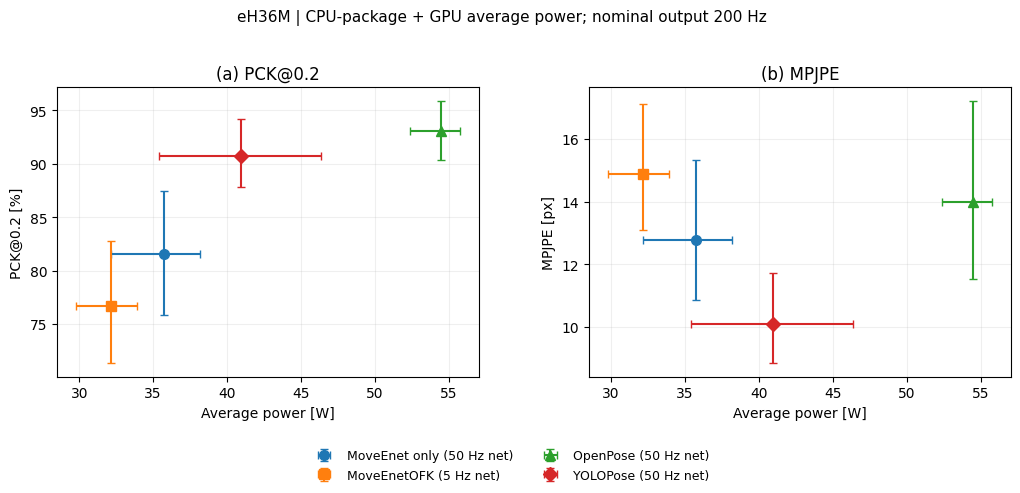

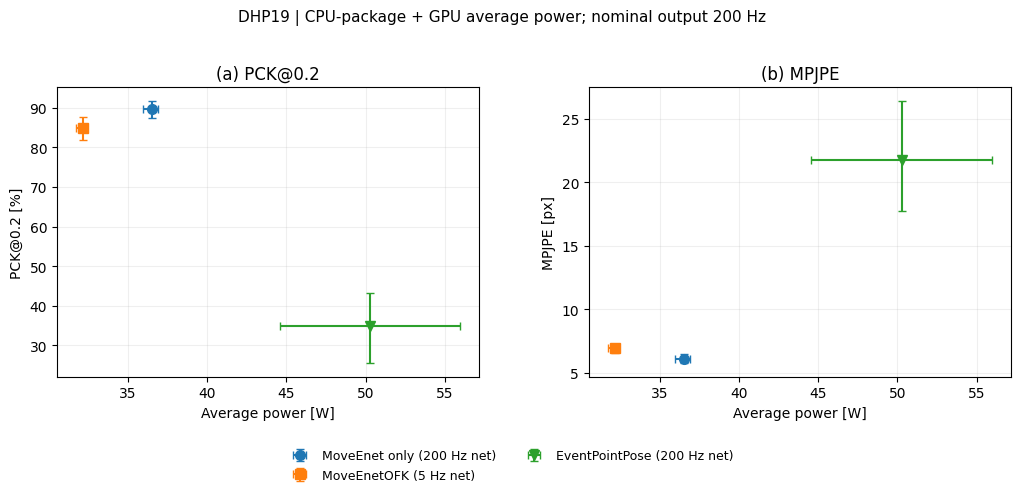

In [9]:
def _asym_err(mean, low, high):
    return np.array([[max(0.0, mean-low)], [max(0.0, high-mean)]])

def plot_power_tradeoff(power_summary, dataset):
    fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.9), sharex=True)
    data = power_summary[power_summary['dataset'] == dataset].set_index('model')

    for ax, metric in zip(axes, ['pck', 'mpjpe']):
        yname = 'pck_weighted_percent' if metric == 'pck' else 'mpjpe_weighted_px'
        for model in fa.MODEL_ORDER[dataset]:
            r = data.loc[model]
            x = float(r['combined_mean_power_w'])
            y = float(r[yname])
            ax.errorbar(
                x, y,
                xerr=_asym_err(x, float(r['power_ci95_low_w']), float(r['power_ci95_high_w'])),
                yerr=_asym_err(y, float(r[metric+'_ci95_low']), float(r[metric+'_ci95_high'])),
                fmt=fa.MARKERS[model], markersize=7, capsize=3,
                linestyle='none',
                label=f"{fa.MODEL_NAMES[model]} ({float(r['net_hz']):g} Hz net)"
            )
        ax.set_xlabel('Average power [W]')
        ax.set_ylabel('PCK@0.2 [%]' if metric == 'pck' else 'MPJPE [px]')
        ax.set_title('(a) PCK@0.2' if metric == 'pck' else '(b) MPJPE')
        ax.grid(alpha=.2)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=2, frameon=False, fontsize=9)
    fig.suptitle(f"{fa.DATASETS[dataset]} | CPU-package + GPU average power; nominal output 200 Hz", fontsize=11)
    fig.subplots_adjust(left=.08, right=.98, bottom=.23, top=.82, wspace=.26)
    return fig

for dataset in ('h36m', 'dhp19'):
    fig = plot_power_tradeoff(power_summary, dataset)
    display(fig)
    fig.savefig(FIGURES / f'{dataset}_power_accuracy{FINAL_FIGURE_SUFFIX}.png', dpi=300, bbox_inches='tight')
    fig.savefig(FIGURES / f'{dataset}_power_accuracy{FINAL_FIGURE_SUFFIX}.svg', bbox_inches='tight')
    plt.close(fig)


## Power vs accuracy — figura unica 2x2

Questa e' l'equivalente in watt della figura `energy_accuracy_both_datasets`.


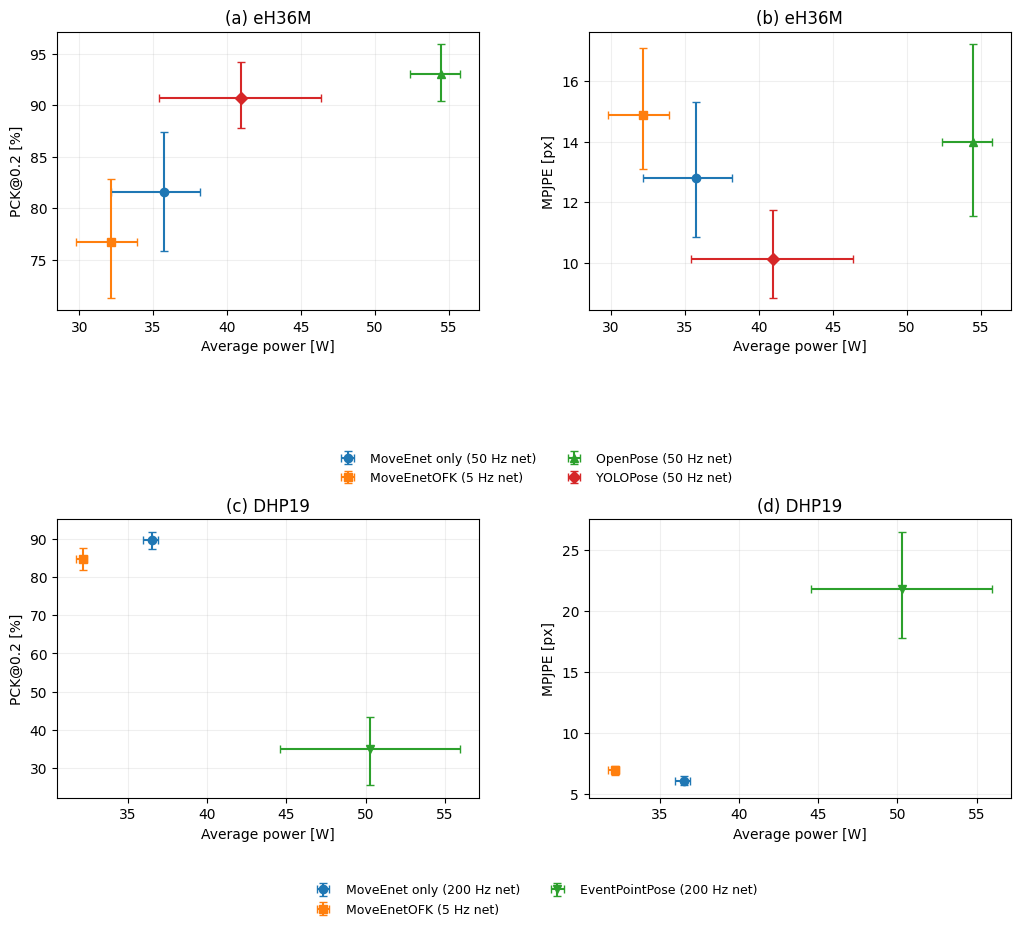

PNG: /data/MoveEnet_OFK_results/Final/energy_accuracy_final_5hz_ofk/figures/power_accuracy_both_datasets_valid_subset.png
SVG: /data/MoveEnet_OFK_results/Final/energy_accuracy_final_5hz_ofk/figures/power_accuracy_both_datasets_valid_subset.svg


In [10]:
def plot_power_tradeoff_all(power_summary):
    fig, axes = plt.subplots(2, 2, figsize=(10.6, 9.7))
    for row, dataset in enumerate(('h36m', 'dhp19')):
        data = power_summary[power_summary['dataset'] == dataset].set_index('model')
        for col, metric in enumerate(('pck', 'mpjpe')):
            ax = axes[row, col]
            yname = 'pck_weighted_percent' if metric == 'pck' else 'mpjpe_weighted_px'
            for model in fa.MODEL_ORDER[dataset]:
                r = data.loc[model]
                x = float(r['combined_mean_power_w'])
                y = float(r[yname])
                ax.errorbar(
                    x, y,
                    xerr=_asym_err(x, float(r['power_ci95_low_w']), float(r['power_ci95_high_w'])),
                    yerr=_asym_err(y, float(r[metric+'_ci95_low']), float(r[metric+'_ci95_high'])),
                    fmt=fa.MARKERS[model], markersize=6, capsize=3,
                    linestyle='none',
                    label=f"{fa.MODEL_NAMES[model]} ({float(r['net_hz']):g} Hz net)"
                )
            ax.set_xlabel('Average power [W]')
            ax.set_ylabel('PCK@0.2 [%]' if metric == 'pck' else 'MPJPE [px]')
            ax.set_title(f"({'abcd'[2*row+col]}) {fa.DATASETS[dataset]}")
            ax.grid(alpha=.2)
        handles, labels = axes[row, 0].get_legend_handles_labels()
        fig.legend(handles, labels, loc='center', bbox_to_anchor=(.53, .49 if row == 0 else .045),
                   ncol=2, frameon=False, fontsize=9)
    fig.subplots_adjust(left=.08, right=.98, bottom=.15, top=.94, hspace=.75, wspace=.26)
    return fig

fig = plot_power_tradeoff_all(power_summary)
display(fig)
fig.savefig(FIGURES / f'power_accuracy_both_datasets{FINAL_FIGURE_SUFFIX}.png', dpi=300, bbox_inches='tight')
fig.savefig(FIGURES / f'power_accuracy_both_datasets{FINAL_FIGURE_SUFFIX}.svg', bbox_inches='tight')
plt.close(fig)
print('PNG:', FIGURES / f'power_accuracy_both_datasets{FINAL_FIGURE_SUFFIX}.png')
print('SVG:', FIGURES / f'power_accuracy_both_datasets{FINAL_FIGURE_SUFFIX}.svg')


## Componenti della potenza media

Come per l'energia, CPU package e GPU device vengono mostrate separatamente. La loro somma e' `combined_mean_power_w`.


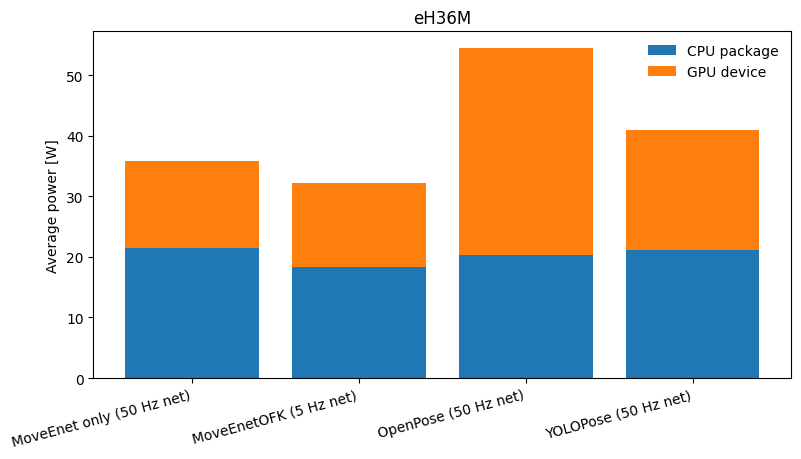

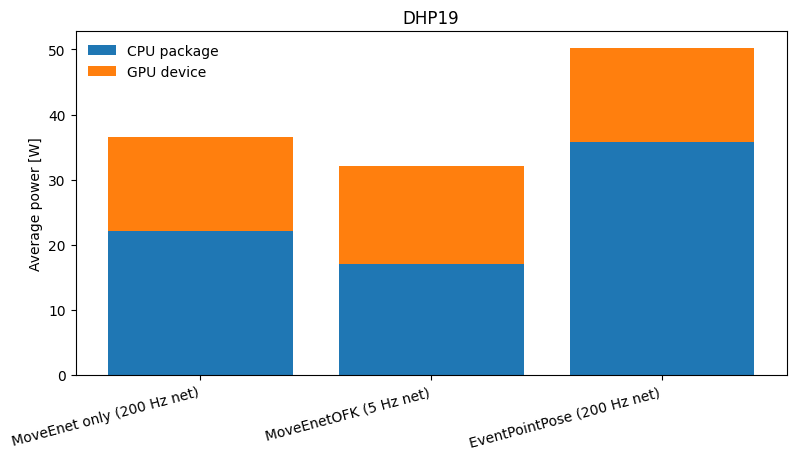

In [11]:
def plot_power_components(power_summary, dataset):
    r = power_summary[power_summary['dataset'] == dataset].set_index('model').loc[fa.MODEL_ORDER[dataset]].reset_index()
    fig, ax = plt.subplots(figsize=(8.2, 4.7))
    x = np.arange(len(r))
    ax.bar(x, r['cpu_mean_power_w'], label='CPU package')
    ax.bar(x, r['gpu_mean_power_w'], bottom=r['cpu_mean_power_w'], label='GPU device')
    ax.set_xticks(x)
    ax.set_xticklabels([f"{fa.MODEL_NAMES[t['model']]} ({float(t['net_hz']):g} Hz net)" for _, t in r.iterrows()], rotation=15, ha='right')
    ax.set_ylabel('Average power [W]')
    ax.set_title(fa.DATASETS[dataset])
    ax.legend(frameon=False)
    fig.tight_layout()
    return fig

for dataset in ('h36m', 'dhp19'):
    fig = plot_power_components(power_summary, dataset)
    display(fig)
    fig.savefig(FIGURES / f'{dataset}_power_components{FINAL_FIGURE_SUFFIX}.png', dpi=300, bbox_inches='tight')
    fig.savefig(FIGURES / f'{dataset}_power_components{FINAL_FIGURE_SUFFIX}.svg', bbox_inches='tight')
    plt.close(fig)
